# Customer Churn Prediction & Segmentation
**Goal:** predict which telecom customers are likely to leave (supervised learning) and group customers into actionable segments (unsupervised learning), so a retention team knows *who* to target and *how*.

**Dataset:** IBM Telco Customer Churn — 7,043 customers, 21 columns (demographics, services, contract, billing, churn label).

**Workflow:** data cleaning → EDA → feature engineering → model comparison with cross-validation → hyperparameter tuning → evaluation on a held-out test set → K-Means segmentation → business recommendations.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src.data_prep import load_raw, clean, add_features, NUMERIC, CATEGORICAL, TARGET
sns.set_theme(style='whitegrid')
raw = load_raw()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality check

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# TotalCharges is stored as text; find values that are not numbers
bad = pd.to_numeric(raw['TotalCharges'], errors='coerce').isna()
print('Non-numeric TotalCharges:', bad.sum())
raw.loc[bad, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Non-numeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 problem rows have `tenure = 0`: they are brand-new customers who haven't been billed yet. So the right fix is `TotalCharges = 0`, not dropping the rows or filling them with the mean.

In [4]:
df = add_features(clean(raw))
print('Missing values after cleaning:', df.isna().sum().sum())
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print(f"Churn rate: {df[TARGET].mean():.1%}  -> imbalanced classes, so accuracy alone is misleading")

Missing values after cleaning: 0
Duplicate customer IDs: 0
Churn rate: 26.5%  -> imbalanced classes, so accuracy alone is misleading


## 2. Exploratory data analysis

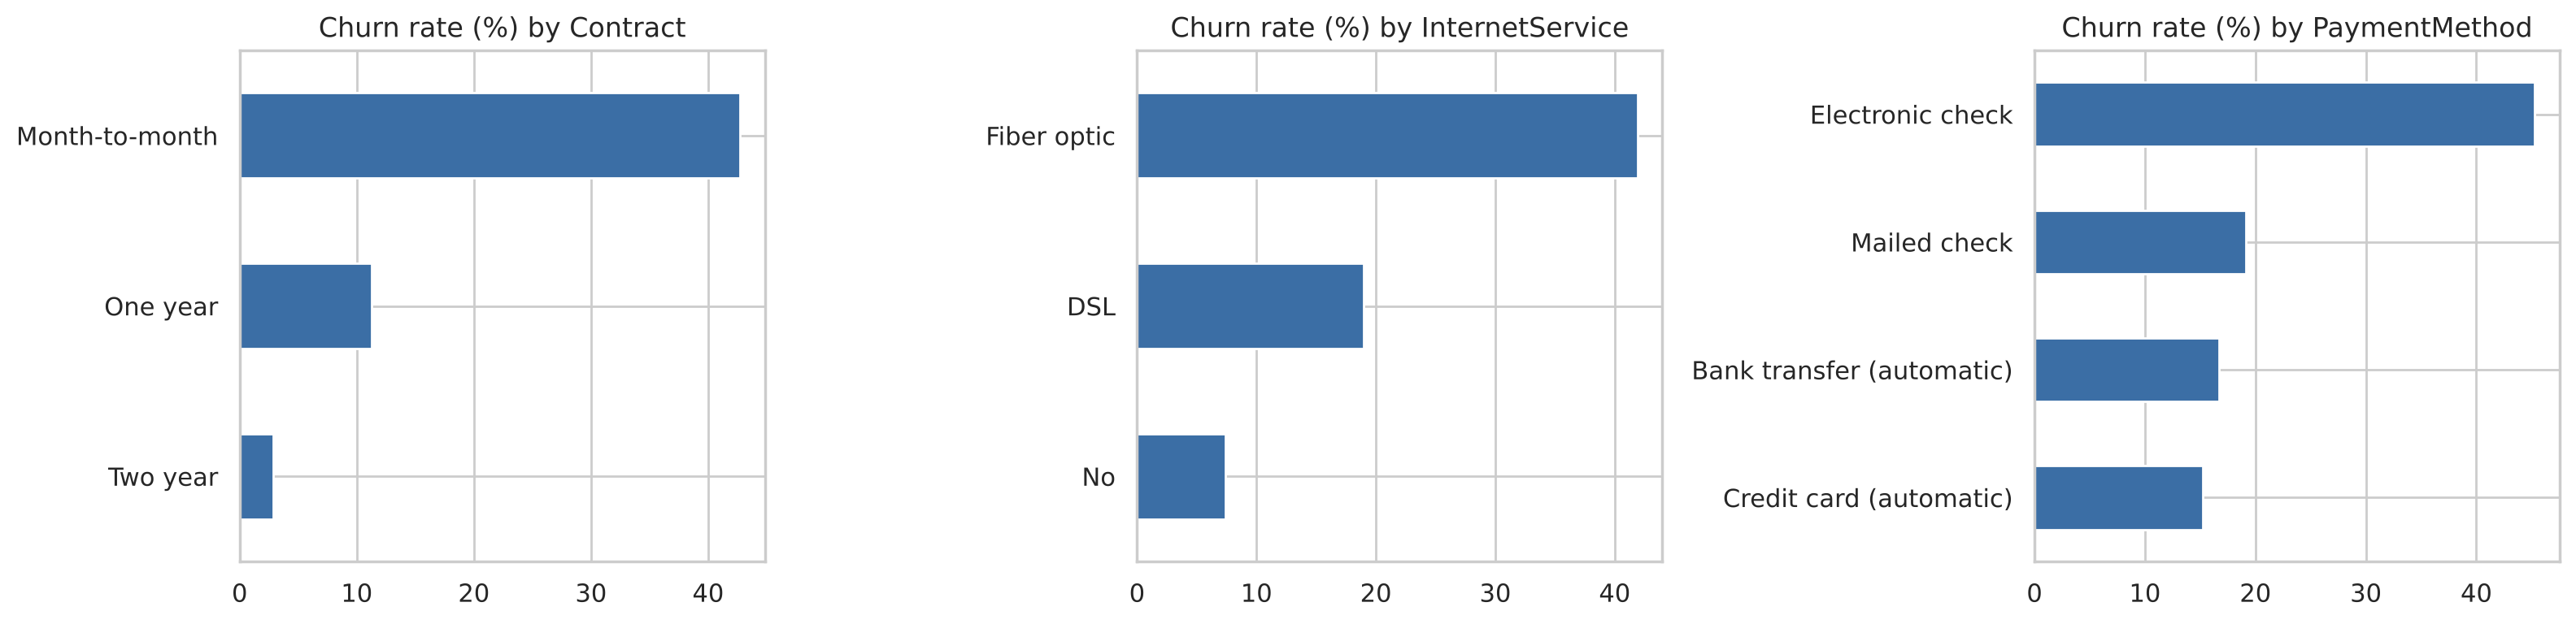

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    (df.groupby(col)[TARGET].mean().sort_values() * 100).plot.barh(ax=ax, color='#3b6ea5')
    ax.set_title(f'Churn rate (%) by {col}'); ax.set_ylabel('')
plt.tight_layout()

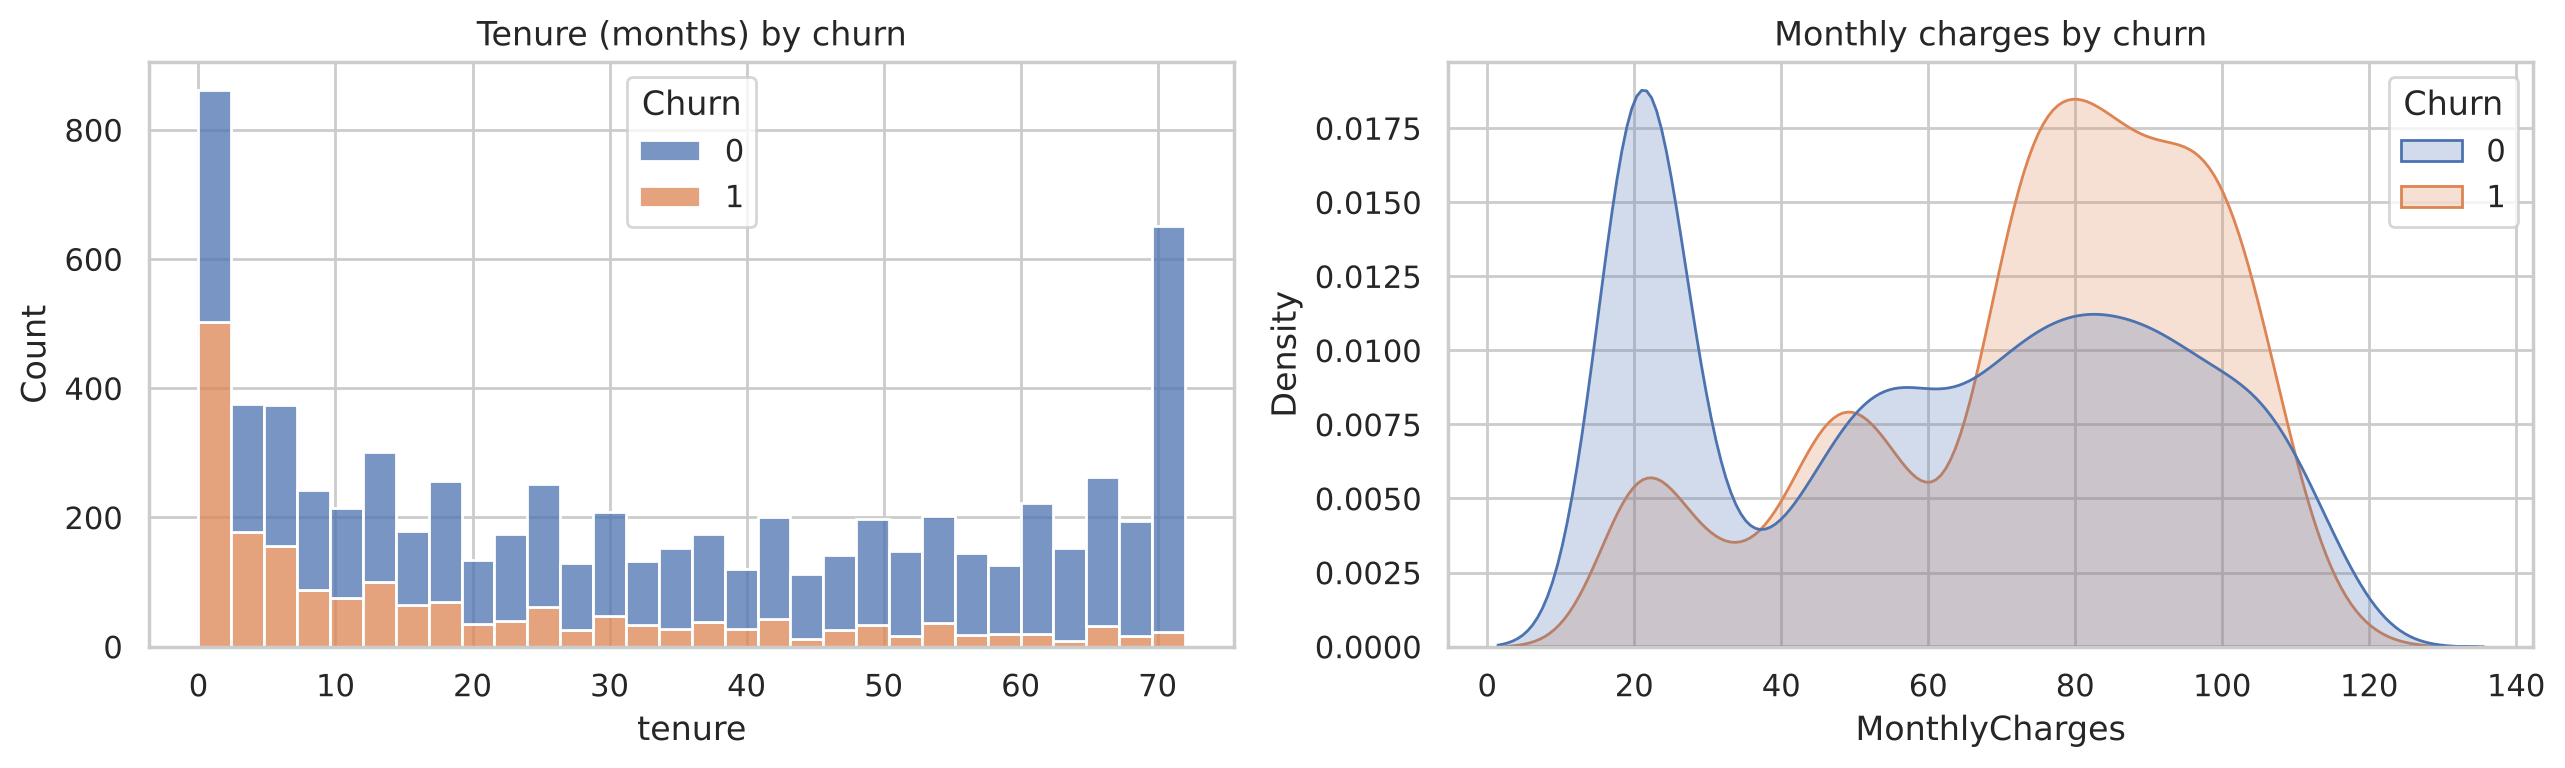

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='tenure', hue=TARGET, bins=30, multiple='stack', ax=axes[0])
axes[0].set_title('Tenure (months) by churn')
sns.kdeplot(data=df, x='MonthlyCharges', hue=TARGET, common_norm=False, fill=True, ax=axes[1])
axes[1].set_title('Monthly charges by churn')
plt.tight_layout()

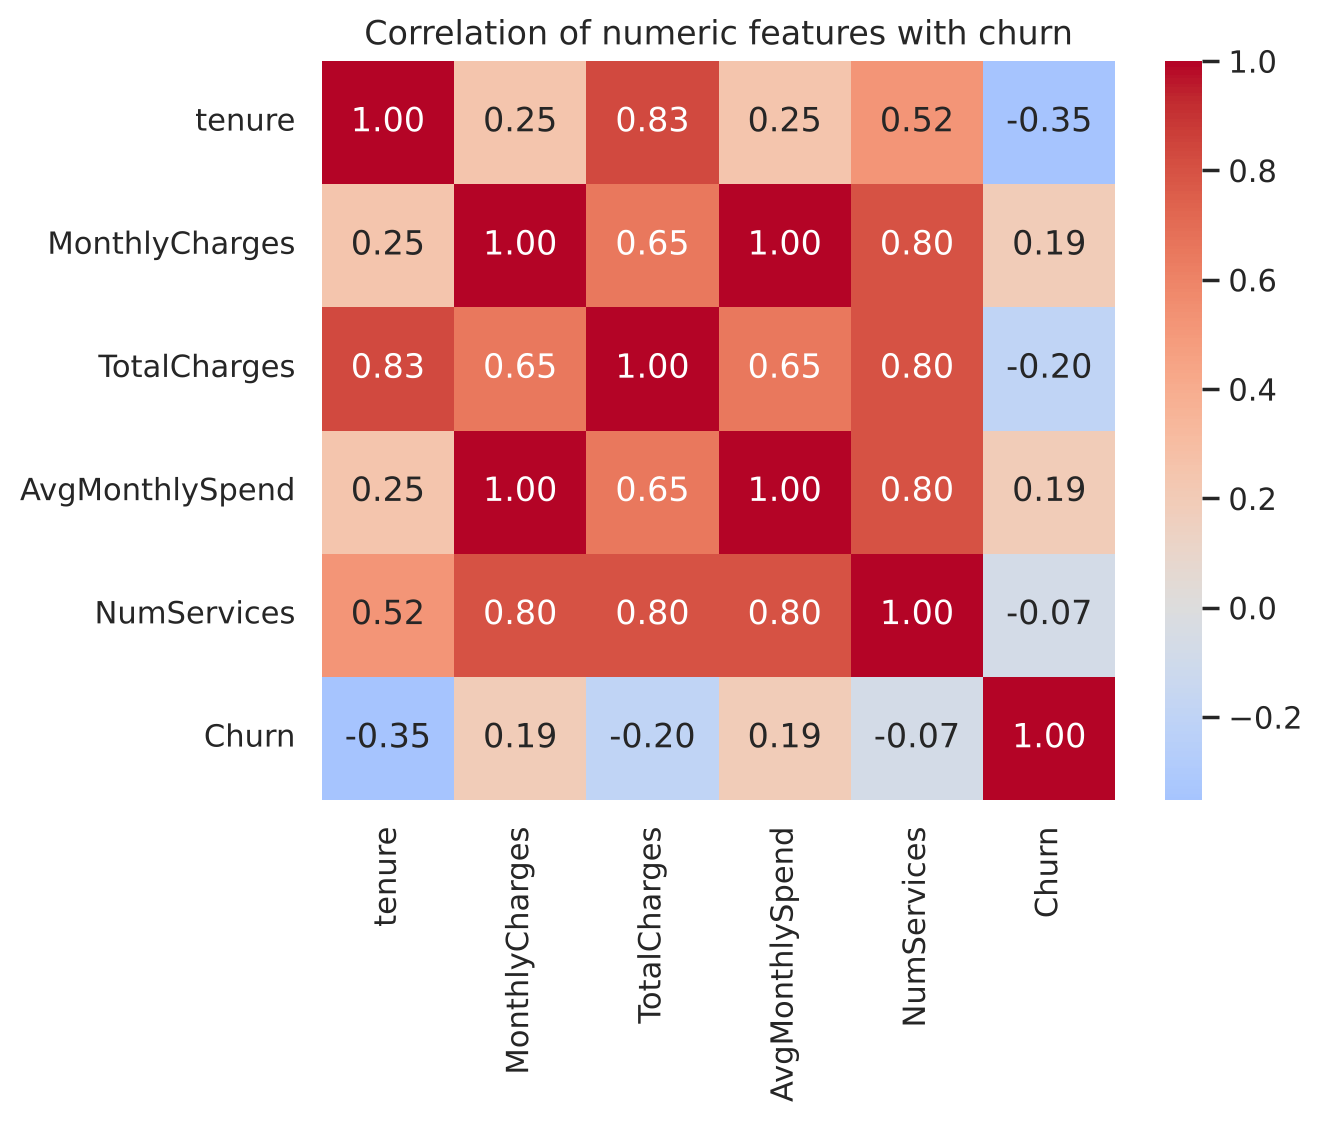

In [7]:
sns.heatmap(df[NUMERIC + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric features with churn');

**EDA takeaways**
- Month-to-month contracts churn far more than one- or two-year contracts.
- Most churn happens in the first year; long-tenure customers rarely leave.
- Fiber-optic and electronic-check customers churn more, and so do customers with higher monthly charges.
- `tenure` and `TotalCharges` are strongly correlated (as expected), so linear models need regularisation.

## 3. Supervised learning: churn prediction
Preprocessing lives in a scikit-learn `Pipeline` (impute → scale numeric, one-hot encode categorical), so every cross-validation fold is preprocessed separately and **no information leaks** from validation data into training.

In [8]:
from sklearn.model_selection import train_test_split
from src.train import compare_models, tune_logreg, best_f1_threshold, evaluate, SEED
X, y = df[NUMERIC + CATEGORICAL], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
comparison = compare_models(X_train, y_train)
comparison.round(3)

,model,roc_auc,f1,recall,precision
0,GradientBoosting,0.847,0.586,0.526,0.662
1,RandomForest,0.846,0.634,0.762,0.543
2,LogisticRegression,0.846,0.628,0.797,0.519


All three models reach a similar ROC-AUC (~0.85). I pick **Logistic Regression** because it performs as well as the tree ensembles while staying easy to explain to a business team. Next I tune it with `GridSearchCV`.

In [9]:
search = tune_logreg(X_train, y_train)
print('Best params:', search.best_params_, '| CV ROC-AUC:', round(search.best_score_, 4))
model = search.best_estimator_
thr = best_f1_threshold(y_train, model.predict_proba(X_train)[:, 1])  # chosen on train data only
metrics, proba, pred = evaluate(model, X_test, y_test, thr)
pd.Series(metrics)

Best params: {'model__C': 0.3, 'model__class_weight': None} | CV ROC-AUC: 0.846


threshold    0.3520
roc_auc      0.8422
accuracy     0.7764
precision    0.5624
recall       0.7112
f1           0.6281
dtype: float64

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stay', 'Churn'], cmap='Blues', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name='Tuned LogReg')
axes[1].plot([0, 1], [0, 1], '--', color='grey')
plt.tight_layout()

**Why tune the threshold?** The default 0.5 cut-off misses many churners. For retention, a missed churner (lost customer) costs more than a false alarm (one discount offer), so I choose the threshold that maximises F1 on the *training* data. This raises recall while keeping precision reasonable.

In [11]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=SEED)
pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(10).plot.barh(color='#3b6ea5')
plt.title('Top features (drop in ROC-AUC when shuffled)');

## 4. Unsupervised learning: customer segmentation
K-Means on scaled `tenure`, `MonthlyCharges` and `NumServices`. I choose *k* with the elbow method and silhouette score.

In [12]:
from src.segment import choose_k, FEATURES
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
Xs = StandardScaler().fit_transform(df[FEATURES])
scores = choose_k(Xs)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(scores.k, scores.inertia, marker='o'); axes[0].set_title('Elbow')
axes[1].plot(scores.k, scores.silhouette, marker='o', color='#c0504d'); axes[1].set_title('Silhouette')
plt.tight_layout()

k = 4 gives a strong silhouette score (only k = 2 is higher), and its four segments are much easier to act on than two.

In [13]:
df['Segment'] = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xs)
profile = df.groupby('Segment').agg(customers=(TARGET, 'size'), avg_tenure=('tenure', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean'), avg_services=('NumServices', 'mean'),
    churn_rate=(TARGET, 'mean'),
    month_to_month=('Contract', lambda s: (s == 'Month-to-month').mean()))
profile.sort_values('churn_rate', ascending=False).round(2)

,customers,avg_tenure,avg_monthly,avg_services,churn_rate,month_to_month
Segment,,,,,,
2,2315,14.79,77.60,3.22,0.47,0.87
0,1557,10.27,29.89,1.26,0.24,0.72
1,2144,56.78,92.10,5.77,0.16,0.27
3,1027,54.56,31.63,1.85,0.05,0.16


## 5. Business recommendations
| Segment | Profile | Churn | Suggested action |
|---|---|---|---|
| New, high-spend | ~15 months, ~$78 per month, mostly month-to-month | **~47%** | Top priority: offer a discount for switching to an annual contract, plus onboarding check-ins |
| New, low-spend | ~10 months, basic plans | ~24% | Bundle cheap add-ons (security, tech support) to increase engagement |
| Loyal, high-spend | ~57 months, many services | ~16% | Protect revenue with a loyalty program and priority support |
| Loyal, low-spend | ~55 months, long contracts | ~5% | Low risk: upsell carefully |

**Combined use:** score every customer with the churn model, then use their segment to pick the retention offer.

## 6. Limitations & next steps
- The dataset is a single snapshot, so the model can't capture how customer behaviour changes over time.
- Next, I'd try gradient boosting with class weights or XGBoost, use SHAP for explanations of individual predictions, and estimate the dollar value of retention offers to set a cost-based threshold.